<a href="https://colab.research.google.com/github/Parvez152977/SMS_Spam_Detection-Naive_Bayes_-_Logistic_Regression-/blob/main/SMS_spam_detection_V_2_(Parvez_Alam).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project: SMS Spam Detection
### Team Member :
                  1. Parvez Alam (111223046)
                  2. Siyma Akter (111223071)
### Dataset     : [UCI SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection)
### Algorithm   : Multinomial Naive Bayes, Logistic Regression
### Environment : Google Colab(Python 3.13)

## Project Workflow

| Step | Description |
|------|-------------|
| 1 | Problem Definition |
| 2 | Data Collection |
| 3 | Data Cleaning & Preprocessing |
| 4 | Exploratory Data Analysis |
| 5 | Feature Engineering (CountVectorizer / TF-IDF) |
| 6 | Model Training (Naive Bayes, Logistic Regression) |
| 7 | Model Evaluation |
| 8 | Prediction on Custom Messages |
| 9 | Training vs Testing Analysis + Feature Importance |

# Machine learning Life cycle - 1: Problem Definition - SMS Spam Detection

### Environment Info (for reproducibility)

In [1]:
import sys
import platform


### Required libraries

In [2]:
import pandas as pd
import numpy as np
import sklearn
import nltk
import matplotlib
import seaborn


In [3]:
print("ENVIRONMENT INFORMATION")
print("=" * 55)
print(f"Platform       : {platform.system()} {platform.release()}")
print(f"Python version : {sys.version.split()[0]}")
print(f"Python binary  : {sys.executable}")
print("=" * 55)
print("LIBRARY VERSIONS")
print("=" * 55)
print(f"pandas         : {pd.__version__}")
print(f"numpy          : {np.__version__}")
print(f"scikit-learn   : {sklearn.__version__}")
print(f"nltk           : {nltk.__version__}")
print(f"matplotlib     : {matplotlib.__version__}")
print(f"seaborn        : {seaborn.__version__}")
print("=" * 55)

ENVIRONMENT INFORMATION
Platform       : Linux 6.6.159+
Python version : 3.13.18
Python binary  : /usr/bin/python3
LIBRARY VERSIONS
pandas         : 2.2.3
numpy          : 2.4.6
scikit-learn   : 1.6.1
nltk           : 3.9.1
matplotlib     : 3.10.0
seaborn        : 0.13.2


##### Report random state used for reproducibility

In [4]:
print("\nREPRODUCIBILITY SETTINGS")
print("=" * 55)
print("Random state   : 42  (used in train_test_split)")
print("Train-test     : 80:20")
print("Max features   : 2500 (CountVectorizer & TfidfVectorizer)")


REPRODUCIBILITY SETTINGS
Random state   : 42  (used in train_test_split)
Train-test     : 80:20
Max features   : 2500 (CountVectorizer & TfidfVectorizer)


# Initial Setup

In [5]:
import pandas as pd

## Machine Learning Life cycle - Step 2-> Data collection

In [6]:
file_path = '/content/drive/MyDrive/Machine_learning_dataset/SMSSpamCollection'

#### Operation in following command:
1. Load the dataset
2. sep='\t' means Tab-Separated
3. header=None means the file has no column names in the first row
4. names=['label', 'message'] gives our columns names manually

In [7]:
df = pd.read_csv(file_path, sep='\t', header=None, names=['label', 'message'])
print("Dataset loaded successfully!")

Dataset loaded successfully!


Now check the dataframe df

In [8]:
df

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


#### Following commands display the first 5 rows to verify it worked

In [9]:
print("Shape of data:", df.shape)

Shape of data: (5572, 2)


In [10]:
print("First 5 rows:")
print(df.head())

First 5 rows:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


Check the balance of the classes (How many spam vs ham?)

In [11]:
print("Class Distribution:")
print(df['label'].value_counts())

Class Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


# Step 3 - Data Cleaning & Preprocessing

In [12]:
import nltk
import re
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer

#### Following command download stopwords (only needs to be done once)

In [13]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

#### Following command initialize the stemmer

In [14]:
ps = PorterStemmer()

#### Create a list to hold our cleaned messages and loop through every message in the dataset

#### Remove all character which aren't necessary

#### re.sub replaces anything that is not necessary

In [15]:
def preprocess_text(text):

    text = str(text).lower()


    text = re.sub(
        r'(https?://\S+|www\.\S+)',
        ' urltoken ',
        text
    )

    text = re.sub(
        r'\b[\w.+-]+@[\w.-]+\.[a-z]{2,}\b',
        ' emailtoken ',
        text
    )

    text = re.sub(
        r'[£$€]\s*\d+(?:[.,]\d+)?',
        ' moneytoken ',
        text
    )

    text = re.sub(
        r'(?<!\w)\+?\d[\d\s().-]{7,}\d(?!\w)',
        ' phonetoken ',
        text
    )

    text = re.sub(
        r'\b\d+(?:[.,]\d+)?\s*%',
        ' percenttoken ',
        text
    )

    text = re.sub(
        r'\b\d+(?:[.,]\d+)?\b',
        ' numbertoken ',
        text
    )

    text = re.sub(r'[^a-zA-Z]', ' ', text)

    words = text.split()

    return ' '.join(words)



corpus = df['message'].apply(preprocess_text).tolist()


for i in range(5):
    print("Original:", df['message'].iloc[i])
    print("Cleaned :", corpus[i])
    print("-" * 60)


Original: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
Cleaned : go until jurong point crazy available only in bugis n great world la e buffet cine there got amore wat
------------------------------------------------------------
Original: Ok lar... Joking wif u oni...
Cleaned : ok lar joking wif u oni
------------------------------------------------------------
Original: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
Cleaned : free entry in numbertoken a wkly comp to win fa cup final tkts st may numbertoken text fa to numbertoken to receive entry question std txt rate t c s apply over s
------------------------------------------------------------
Original: U dun say so early hor... U c already then say...
Cleaned : u dun say so early hor u c already then say
-------------------------------------------------------

In [16]:
print(corpus[:50])

['go until jurong point crazy available only in bugis n great world la e buffet cine there got amore wat', 'ok lar joking wif u oni', 'free entry in numbertoken a wkly comp to win fa cup final tkts st may numbertoken text fa to numbertoken to receive entry question std txt rate t c s apply over s', 'u dun say so early hor u c already then say', 'nah i don t think he goes to usf he lives around here though', 'freemsg hey there darling it s been numbertoken week s now and no word back i d like some fun you up for it still tb ok xxx std chgs to send moneytoken to rcv', 'even my brother is not like to speak with me they treat me like aids patent', 'as per your request melle melle oru minnaminunginte nurungu vettam has been set as your callertune for all callers press numbertoken to copy your friends callertune', 'winner as a valued network customer you have been selected to receivea moneytoken prize reward to claim call phonetoken claim code kl valid numbertoken hours only', 'had your mobi

#### Now we convert the labels: ham = 0, spam = 1
#### We use map() to replace the text labels with numbers

In [17]:
df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

In [18]:
df

,label,message,label_num
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0
...,...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...,1
5568,ham,Will ü b going to esplanade fr home?,0
5569,ham,"Pity, * was in mood for that. So...any other s...",0
5570,ham,The guy did some bitching but I acted like i'd...,0


#### Let's see the difference between the original and cleaned message

In [19]:
print("Original Message (Row 2):")
print(df['message'][2])

Original Message (Row 2):
Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's


In [20]:
print("\nCleaned Message (Row 2):")
print(corpus[2])


Cleaned Message (Row 2):
free entry in numbertoken a wkly comp to win fa cup final tkts st may numbertoken text fa to numbertoken to receive entry question std txt rate t c s apply over s


In [21]:
print("\n" + "="*50)
print("Original Message (Row 10 - likely spam):")
print(df['message'][10])
print("\nCleaned Message (Row 10):")
print(corpus[10])


Original Message (Row 10 - likely spam):
I'm gonna be home soon and i don't want to talk about this stuff anymore tonight, k? I've cried enough today.

Cleaned Message (Row 10):
i m gonna be home soon and i don t want to talk about this stuff anymore tonight k i ve cried enough today


# Step 4: Exploratory Data Analysis (EDA)

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from wordcloud import WordCloud

## 1. Visualize Class Balance

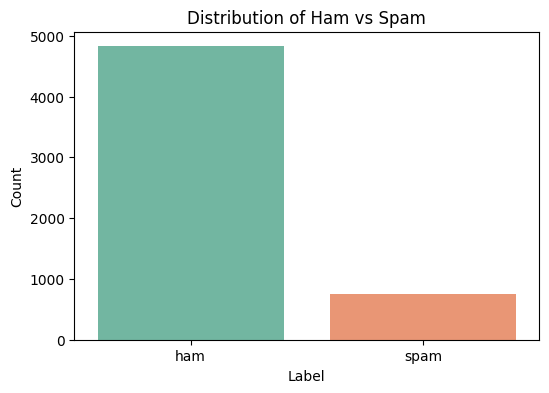

In [23]:
plt.figure(figsize=(6,4))
sns.countplot(x='label', data=df, hue='label', palette='Set2', legend=False)
plt.title('Distribution of Ham vs Spam')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()

## 2. Message Length Analysis

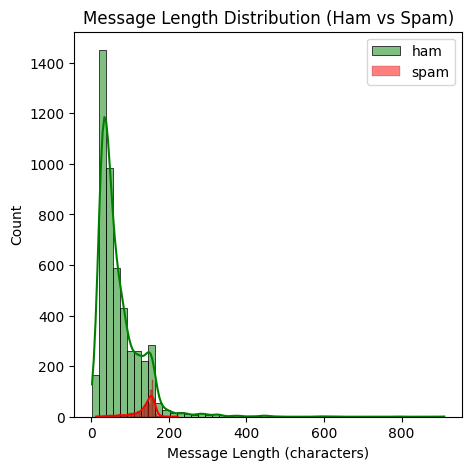

In [24]:
df['length'] = df['message'].apply(len)

plt.figure(figsize=(5,5))
sns.histplot(df[df['label']=='ham']['length'], bins=50, color='green', label='ham', kde=True)
sns.histplot(df[df['label']=='spam']['length'], bins=50, color='red', label='spam', kde=True)
plt.title('Message Length Distribution (Ham vs Spam)')
plt.xlabel('Message Length (characters)')
plt.legend()
plt.show()


In [25]:
print("Average length of HAM messages:", df[df['label']=='ham']['length'].mean())
print("Average length of SPAM messages:", df[df['label']=='spam']['length'].mean())


Average length of HAM messages: 71.48248704663213
Average length of SPAM messages: 138.6706827309237


### 3. Most Common Words in SPAM

In [26]:
spam_words = ' '.join([corpus[i] for i in range(len(df)) if df['label_num'][i] == 1]).split()
ham_words  = ' '.join([corpus[i] for i in range(len(df)) if df['label_num'][i] == 0]).split()

In [27]:
print("\nTop 15 words in SPAM:")
print(Counter(spam_words).most_common(15))

print("\nTop 15 words in HAM:")
print(Counter(ham_words).most_common(15))


Top 15 words in SPAM:
[('numbertoken', 1204), ('to', 691), ('phonetoken', 444), ('a', 393), ('call', 370), ('moneytoken', 325), ('you', 299), ('your', 264), ('free', 228), ('the', 206), ('for', 204), ('now', 203), ('or', 192), ('u', 180), ('p', 180)]

Top 15 words in HAM:
[('i', 2962), ('you', 1948), ('to', 1562), ('the', 1137), ('a', 1073), ('u', 1042), ('numbertoken', 887), ('and', 858), ('in', 825), ('me', 777), ('my', 755), ('is', 739), ('it', 718), ('that', 561), ('of', 526)]


### 4. Word Clouds

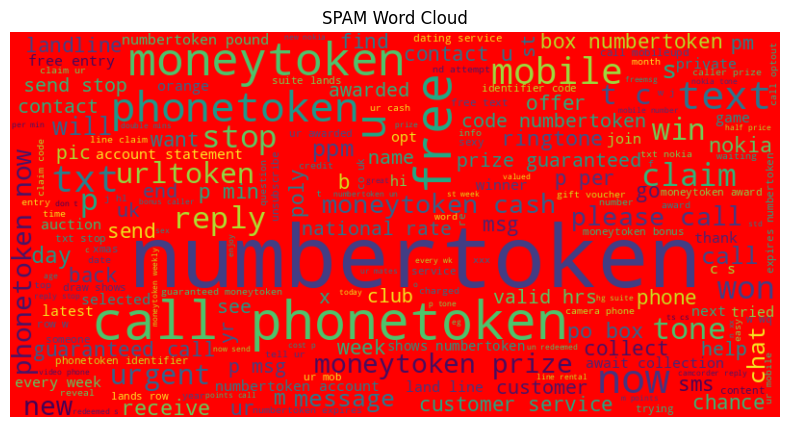

In [28]:
# Spam word cloud

spam_wc = WordCloud(width=800, height=400, background_color='red').generate(' '.join(spam_words))
plt.figure(figsize=(10,5))
plt.imshow(spam_wc, interpolation='bilinear')
plt.axis('off')
plt.title('SPAM Word Cloud')
plt.show()

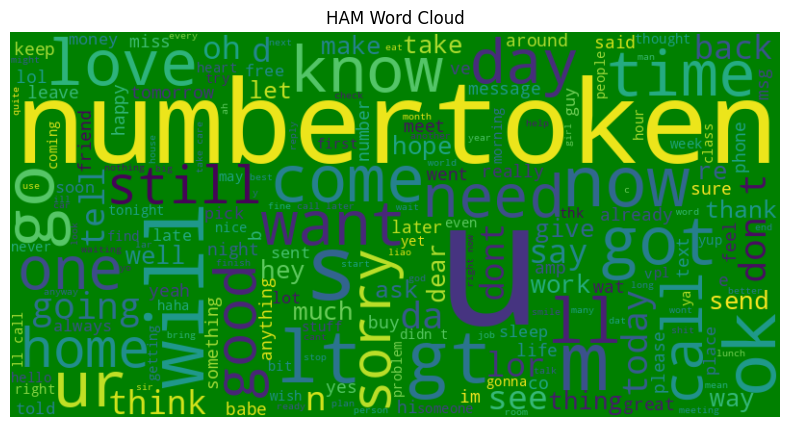

In [29]:
# Ham word cloud

ham_wc = WordCloud(width=800, height=400, background_color='green').generate(' '.join(ham_words))
plt.figure(figsize=(10,5))
plt.imshow(ham_wc, interpolation='bilinear')
plt.axis('off')
plt.title('HAM Word Cloud')
plt.show()

# Step 5 - Feature Engineering

### Feature engineering (Bag of words)

In [30]:
from sklearn.feature_extraction.text import CountVectorizer

# 1. Split the data
### test_size=0.2 → 20% for testing, 80% for training
### random_state=42 → ensures we get the same split every time (reproducibility)

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
import numpy as np

In [32]:
Y = df['label_num'].values

corpus_train, corpus_test, Y_train, Y_test = train_test_split(
    corpus,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

In [33]:
print("\nTRAIN-TEST SPLIT")
print("=" * 40)
print("Training messages:", len(corpus_train))
print("Testing messages :", len(corpus_test))
print("Training labels  :", Y_train.shape)
print("Testing labels   :", Y_test.shape)


TRAIN-TEST SPLIT
Training messages: 4457
Testing messages : 1115
Training labels  : (4457,)
Testing labels   : (1115,)


### The following commands -
  -Initialize the CountVectorizer
  -Max_feature=2500 means we only keep the top 2500 most frequent words
  -(This reduces the size of the vectors and speed up training)

In [34]:
cv = CountVectorizer(max_features=2500)

### Fit and transform the corpus into a mumerical matrix

In [35]:
X_train = cv.fit_transform(corpus_train).toarray()
X_test = cv.transform(corpus_test).toarray()

In [36]:
print("Shape of X(features):", X_train.shape)
print("Shape of X(features):", X_test.shape)
print("Shape of Y (lebels)", Y.shape)

Shape of X(features): (4457, 2500)
Shape of X(features): (1115, 2500)
Shape of Y (lebels) (5572,)


### Let's peek at what the vectors look like

In [37]:
print("\nFirst 10 words in our vocabulary:")
print(cv.get_feature_names_out()[:15])


First 10 words in our vocabulary:
['aah' 'aathi' 'abiola' 'able' 'about' 'abt' 'ac' 'acc' 'accept' 'access'
 'accident' 'accidentally' 'accordingly' 'account' 'ache']


### Show the actual text of the first message for comparison

In [38]:
print("\nOriginal first message:", df['message'][0])


Original first message: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...


### Show the Convertion of the first message for comparison

In [39]:
print("\nFirst message converted to numbers (first 30 values):")
print(X_train[0][:30])


First message converted to numbers (first 30 values):
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


### Step 5: Feature Engineering for Logistic Regression.

In [40]:
from sklearn.feature_extraction.text import TfidfVectorizer

##### Initialize TF-IDF

In [41]:
tfidf = TfidfVectorizer(max_features=2500)

#### Transform the cleaned corpus

In [42]:
X_train_tfidf = tfidf.fit_transform(corpus_train)
X_test_tfidf = tfidf.transform(corpus_test)


print("Shape of TF-IDF X_train_tfidf", X_train_tfidf.shape)
print("Shape of TF-IDF X_test_tfidf", X_test_tfidf.shape)
print("Shape of Y", Y.shape)

Shape of TF-IDF X_train_tfidf (4457, 2500)
Shape of TF-IDF X_test_tfidf (1115, 2500)
Shape of Y (5572,)


#### showing some feature names

In [43]:
print("\nSample words in vocabulary:", tfidf.get_feature_names_out()[:10])


Sample words in vocabulary: ['aah' 'aathi' 'abiola' 'able' 'about' 'abt' 'ac' 'acc' 'accept' 'access']


### Now comparing Logistic Regression with Naiyeb bayes

In [44]:
print("\nDifference between CountVectorizer and TF-IDF for first message")
print("\nCountVectorizer values (first 30 features):")
print(X_train[0][:30])
print("\nTF-IDF values (first 30 features):")
print(X_train_tfidf[0].toarray()[0][:30])


Difference between CountVectorizer and TF-IDF for first message

CountVectorizer values (first 30 features):
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

TF-IDF values (first 30 features):
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0.]


# Step 6: Model Selection & Training

### 2. Initialize the model

In [45]:
model = MultinomialNB()

### 3. Train the model
### .fit() is where the actual "learning" happens

In [46]:
model.fit(X_train, Y_train)


MultinomialNB()

In [47]:
print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)


Training set size: (4457, 2500)
Testing set size: (1115, 2500)


### 4. Show class priors

In [48]:
print("\n Model trained successfully!")
print("Number of classes learned:", model.classes_)



 Model trained successfully!
Number of classes learned: [0 1]


### class_count_ = number of samples per class in training data
### class_log_prior_ = log of the prior probability

In [49]:
print("\nClass counts in training data:", model.class_count_)
print("Class log priors:", model.class_log_prior_)


Class counts in training data: [3859.  598.]
Class log priors: [-0.14406781 -2.00864042]


### Convert log priors back to actual probabilities using exp()

In [50]:
priors = np.exp(model.class_log_prior_)
print("Class priors (ham, spam):", priors)

Class priors (ham, spam): [0.86582903 0.13417097]


## Step - 6 : Model Selection & training for Logistic Regression

##### Train/test Split for TF-IDF data

### Train Logistic Regression

In [51]:
from sklearn.linear_model import LogisticRegression

##### Initialize the model with max_iter=1000 to ensure th runs enough iterations to coverage

In [52]:
lr_model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

##### Now train the model

In [53]:
lr_model.fit(X_train_tfidf, Y_train)

print("Logistic Regression trained successfully..")
print("Number of classes: ", lr_model.classes_)

print("Number of coefficient(features): ", len(lr_model.coef_[0]))

Logistic Regression trained successfully..
Number of classes:  [0 1]
Number of coefficient(features):  2500


### Training vs Testing Metrics

In [54]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [55]:
def get_matrics(model, X_train, Y_train, X_test, Y_test, name):
  """Return training and testing metrics for a classification model."""
  Y_train_pred = model.predict(X_train)
  Y_test_pred = model.predict(X_test)

  train_row = {
      'Model' : name,
      'Split' : 'Training',
      'Accuracy' : accuracy_score(Y_train, Y_train_pred),
      'Precision' : precision_score(Y_train, Y_train_pred),
      'Recall' : recall_score(Y_train, Y_train_pred),
      'F1_Score' : f1_score(Y_train, Y_train_pred)
  }
  test_row = {
      'Model' : name,
      'Split' : 'Testing',
      'Accuracy' : accuracy_score(Y_test, Y_test_pred),
      'Precision' : precision_score(Y_test, Y_test_pred),
      'Recall' : recall_score(Y_test, Y_test_pred),
      'F1_Score' : f1_score(Y_test, Y_test_pred)
  }
  return train_row, test_row


### Naive Bayes (trained on CountVectorizer features)

In [56]:
train_nb, test_nb = get_matrics(
    model, X_train, Y_train, X_test, Y_test, 'Naive Bayes'
)

### Logistic Regression (trained on TF-IDF features)

In [57]:
train_lr, test_lr = get_matrics(
    lr_model, X_train_tfidf, Y_train, X_test_tfidf, Y_test, 'Logistic Regression'
)

In [58]:
results_df = pd.DataFrame([train_nb, test_nb, train_lr,test_lr])

print("Training vs Testing Metrics")
print("-"*50)
print(results_df.round(4).to_string(index=False))

Training vs Testing Metrics
--------------------------------------------------
              Model    Split  Accuracy  Precision  Recall  F1_Score
        Naive Bayes Training    0.9901     0.9586  0.9682    0.9634
        Naive Bayes  Testing    0.9874     0.9655  0.9396    0.9524
Logistic Regression Training    0.9901     0.9439  0.9849    0.9640
Logistic Regression  Testing    0.9857     0.9404  0.9530    0.9467


### Overfitting analysis

In [59]:
# Overfitting Analysis (compute in loop, print after)

print("\nOVERFITTING ANALYSIS (Accuracy gap = Training − Testing)")
print("=" * 80)

# Collect results from BOTH models in a list
analysis_results = []

for name in ['Naive Bayes', 'Logistic Regression']:
    # Get training accuracy
    train_rows = results_df[(results_df['Model'] == name) & (results_df['Split'] == 'Training')]
    train_acc = float(train_rows['Accuracy'].iloc[0])

    # Get testing accuracy
    test_rows = results_df[(results_df['Model'] == name) & (results_df['Split'] == 'Testing')]
    test_acc = float(test_rows['Accuracy'].iloc[0])

    gap = train_acc - test_acc

    if gap > 0.02:
        verdict = "Possible OVERFITTING"
    elif gap < -0.02:
        verdict = "Possible UNDERFITTING"
    else:
        verdict = "Healthy fit (gap < 2%)"

    # Save to list
    analysis_results.append({
        'name': name,
        'train': train_acc,
        'test': test_acc,
        'gap': gap,
        'verdict': verdict
    })


for result in analysis_results:
    print("{}  Train = {:.4f} | Test = {:.4f} | Gap = {:+.4f}  ->  {}".format(
        result['name'], result['train'], result['test'], result['gap'], result['verdict']
    ))

# Step 3: Sanity check — how many results were collected?
print("\n--- Collected {} models ---".format(len(analysis_results)))


OVERFITTING ANALYSIS (Accuracy gap = Training − Testing)
Naive Bayes  Train = 0.9901 | Test = 0.9874 | Gap = +0.0027  ->  Healthy fit (gap < 2%)
Logistic Regression  Train = 0.9901 | Test = 0.9857 | Gap = +0.0045  ->  Healthy fit (gap < 2%)

--- Collected 2 models ---


In [60]:

# Diagnostic 1: Check what's in results_df
print("Models in results_df:")
print(results_df['Model'].unique())
print("\nFull results_df:")
print(results_df)

Models in results_df:
['Naive Bayes' 'Logistic Regression']

Full results_df:
                 Model     Split  Accuracy  Precision    Recall  F1_Score
0          Naive Bayes  Training  0.990128   0.958609  0.968227  0.963394
1          Naive Bayes   Testing  0.987444   0.965517  0.939597  0.952381
2  Logistic Regression  Training  0.990128   0.943910  0.984950  0.963993
3  Logistic Regression   Testing  0.985650   0.940397  0.953020  0.946667


##### Get vocabulary and coefficients from the trained LR model

In [61]:
feature_names = tfidf.get_feature_names_out()
coefficients  = lr_model.coef_[0]


coef_df = pd.DataFrame({
    'word':        feature_names,
    'coefficient': coefficients
}).sort_values('coefficient', ascending=False).reset_index(drop=True)


In [62]:
print("TOP 15 WORDS PUSHING TOWARD SPAM (positive coefficients)")
print("=" * 60)
print(coef_df.head(15).to_string(index=False))

print("\nTOP 15 WORDS PUSHING TOWARD HAM (most negative coefficients)")
print("=" * 60)
print(coef_df.tail(15).iloc[::-1].to_string(index=False))


TOP 15 WORDS PUSHING TOWARD SPAM (positive coefficients)
       word  coefficient
 phonetoken     8.293102
numbertoken     5.948914
 moneytoken     5.357282
   urltoken     4.284914
        txt     4.124623
       text     3.492961
       free     3.234074
      reply     2.962680
         to     2.939991
       stop     2.903204
       your     2.880454
       call     2.761337
         uk     2.756251
     mobile     2.635684
    service     2.539752

TOP 15 WORDS PUSHING TOWARD HAM (most negative coefficients)
 word  coefficient
   my    -2.209000
   me    -2.134291
   lt    -1.816064
   gt    -1.812862
 that    -1.461502
   ll    -1.448861
   ok    -1.431478
  but    -1.334360
   at    -1.260819
 home    -1.200264
 come    -1.187922
 when    -1.179771
   da    -1.157094
   he    -1.152274
later    -1.133177


# Step 7: Model Evaluation

In [63]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
import seaborn as sns
import matplotlib.pyplot as plt


### 1. Make predictions on the test set

In [64]:
Y_pred = model.predict(X_test)

In [65]:
print(Y_pred)

[0 0 0 ... 0 0 0]


### 2. Calculate metrics

In [66]:
accuracy = accuracy_score(Y_test, Y_pred)
precision = precision_score(Y_test, Y_pred)
recall = recall_score(Y_test, Y_pred)
f1 = f1_score(Y_test, Y_pred)

In [67]:
print("Naive Bayes PERFORMANCE METRICS")
print("="*40)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

Naive Bayes PERFORMANCE METRICS
Accuracy : 0.9874
Precision: 0.9655
Recall   : 0.9396
F1-Score : 0.9524


### 3. Full classification report

In [68]:
print("\nNaive Bayes DETAILED CLASSIFICATION REPORT")
print("="*40)
print(classification_report(Y_test, Y_pred, target_names=['Ham', 'Spam']))


Naive Bayes DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       966
        Spam       0.97      0.94      0.95       149

    accuracy                           0.99      1115
   macro avg       0.98      0.97      0.97      1115
weighted avg       0.99      0.99      0.99      1115



### 4. Confusion Matrix

In [69]:
cm = confusion_matrix(Y_test, Y_pred)

In [70]:
print("\nNaive Bayes CONFUSION MATRIX")
print("="*40)
print(f"                Predicted Ham   Predicted Spam")
print(f"Actual Ham      {cm[0][0]:<15} {cm[0][1]}")
print(f"Actual Spam     {cm[1][0]:<15} {cm[1][1]}")


Naive Bayes CONFUSION MATRIX
                Predicted Ham   Predicted Spam
Actual Ham      961             5
Actual Spam     9               140


### 5. Visualize the confusion matrix

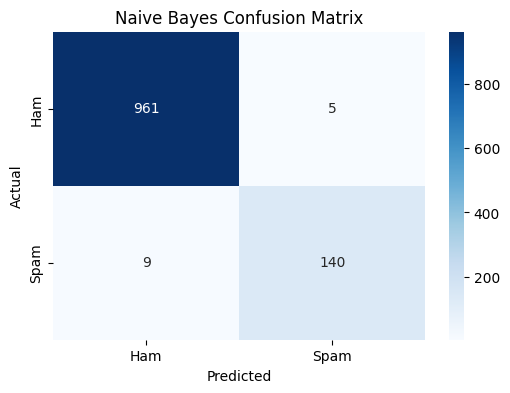

In [71]:
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Ham', 'Spam'],
            yticklabels=['Ham', 'Spam'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Naive Bayes Confusion Matrix')
plt.show()

### Logistic Regression Evaluation

In [72]:
Y_pred_lr = lr_model.predict(X_test_tfidf)

##### Calculate matrics

In [73]:
print("LOGISTIC REGRESSION PERFORMANCE")
print("="*40)
print(f"Accuracy : {accuracy_score(Y_test, Y_pred_lr):.4f}")
print(f"Accuracy : {precision_score(Y_test, Y_pred_lr):.4f}")
print(f"Accuracy : {recall_score(Y_test, Y_pred_lr):.4f}")
print(f"Accuracy : {f1_score(Y_test, Y_pred_lr):.4f}")

LOGISTIC REGRESSION PERFORMANCE
Accuracy : 0.9857
Accuracy : 0.9404
Accuracy : 0.9530
Accuracy : 0.9467


##### Classification Report

In [74]:
print("\nLogistic Regression CLASSIFICATION REPORT")
print("="*40)
print(classification_report(Y_test, Y_pred_lr, target_names=['Ham','Spam']))


Logistic Regression CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       966
        Spam       0.94      0.95      0.95       149

    accuracy                           0.99      1115
   macro avg       0.97      0.97      0.97      1115
weighted avg       0.99      0.99      0.99      1115



### Confusion Matrix

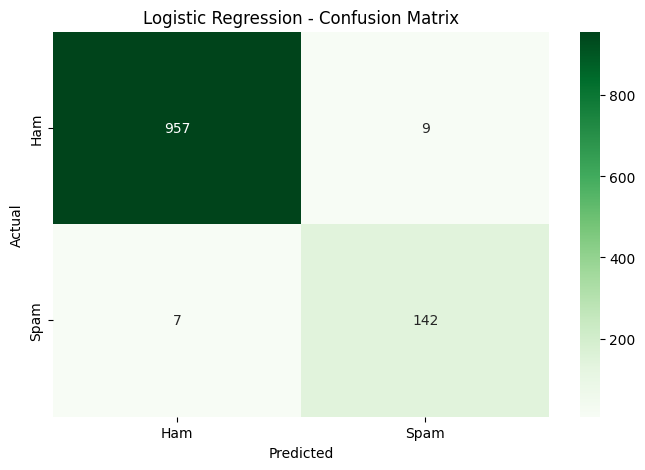

In [75]:
cm_lr = confusion_matrix(Y_test, Y_pred_lr)

plt.figure(figsize=(8,5))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Greens', xticklabels=['Ham', 'Spam'], yticklabels=['Ham','Spam'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

### Comparing Naive Bayes VS Logistic Regression

#### Re-train Naive Bayes on the TF-IDF features for a fair comparison

##### Earlier NB was trained on CountVectorizer; Now we compare on TF-IDF

In [76]:
nb_model_tfidf = MultinomialNB()
nb_model_tfidf.fit(X_train_tfidf, Y_train)
Y_pred_nb_tfidf = nb_model_tfidf.predict(X_test_tfidf)

##### Create a comparison table

In [77]:
comparison = pd.DataFrame({
    'Metric':['Accuracy','Precision','Recall','F1-Score'],
    'Naive Bayes (TF-IDF)':[
        accuracy_score(Y_test, Y_pred_nb_tfidf),
        precision_score(Y_test, Y_pred_nb_tfidf),
        recall_score(Y_test, Y_pred_nb_tfidf),
        f1_score(Y_test, Y_pred_nb_tfidf)
    ],
    'Logistic Regression (TF-IDF)':[
        accuracy_score(Y_test, Y_pred_lr),
        precision_score(Y_test, Y_pred_lr),
        recall_score(Y_test, Y_pred_lr),
        f1_score(Y_test, Y_pred_lr)
    ]
})


print("Model Comparison (Both on TF-IDF)")
print("="*60)
print(comparison.round(4).to_string(index=False))

Model Comparison (Both on TF-IDF)
   Metric  Naive Bayes (TF-IDF)  Logistic Regression (TF-IDF)
 Accuracy                0.9767                        0.9857
Precision                1.0000                        0.9404
   Recall                0.8255                        0.9530
 F1-Score                0.9044                        0.9467


# Step 8: Testing the Model with Custom Messages (Mini "Deployment")

In [78]:
import re
import numpy as np
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer

In [79]:
ps = PorterStemmer()

### Data cleanning process repeat as befor in step 3

In [80]:
def clean_message(message):
    """Apply exactly the same preprocessing used during training."""
    text = str(message).lower()

    # Preserve useful spam-related indicators
    text = re.sub(r'(https?://\S+|www\.\S+)', ' urltoken ', text)
    text = re.sub(r'\b[\w.+-]+@[\w.-]+\.[a-z]{2,}\b', ' emailtoken ', text)
    text = re.sub(r'[£$€]\s*\d+(?:[.,]\d+)?', ' moneytoken ', text)
    text = re.sub(r'(?<!\w)\+?\d[\d\s().-]{7,}\d(?!\w)', ' phonetoken ', text)
    text = re.sub(r'\b\d+(?:[.,]\d+)?\s*%', ' percenttoken ', text)
    text = re.sub(r'\b\d+(?:[.,]\d+)?\b', ' numbertoken ', text)

    # Keep alphabetic tokens, including the placeholders
    text = re.sub(r'[^a-zA-Z]', ' ', text)

    return ' '.join(text.split())


### Prediction with Naive Bayes

In [81]:
def predict_message(message):
    """Predict using Naive Bayes + CountVectorizer."""
    cleaned = clean_message(message)

    # Use the CountVectorizer fitted during training
    vector = cv.transform([cleaned])

    prediction = model.predict(vector)[0]
    probabilities = model.predict_proba(vector)[0]

    confidence = probabilities[
        list(model.classes_).index(prediction)
    ] * 100

    label = "SPAM" if prediction == 1 else "HAM"

    print(f"Message    : {message}")
    print(f"Cleaned    : {cleaned}")
    print(f"Prediction : {label} (confidence: {confidence:.2f}%)")
    print("-" * 60)


### Prediction with Logistic Regression

In [82]:
def predict_with_lr(message):
    """Predict using Logistic Regression + TF-IDF."""
    cleaned = clean_message(message)

    # Use the TF-IDF vectorizer fitted during training
    vector = tfidf.transform([cleaned])

    prediction = lr_model.predict(vector)[0]
    probabilities = lr_model.predict_proba(vector)[0]

    confidence = probabilities[
        list(lr_model.classes_).index(prediction)
    ] * 100

    label = "SPAM" if prediction == 1 else "HAM"

    print(f"Message    : {message}")
    print(f"Cleaned    : {cleaned}")
    print(f"Prediction : {label} (confidence: {confidence:.2f}%)")
    print("-" * 60)


# Testing

In [83]:
print("TESTING THE MODEL ON NEW MESSAGES")
print("=" * 60)

# Test messages (mix of obvious spam, obvious ham, and tricky ones)
test_messages = [
    "Hey, are we still meeting for lunch tomorrow?",
    "Congratulations! You've WON a £1000 cash prize. Call 09061701461 to claim now!",
    "Can you pick up some milk on your way home?",
    "URGENT! Your mobile number has been awarded a £2000 bonus. Call now to claim!",
    "Mom, I'll be home late tonight, don't wait up.",
    "Free entry in a weekly competition to win FA Cup final tickets. Text FA to 87121",
    "Just finished my homework, feeling so relieved!",
    "You have 1 new voicemail. Call 08718726270 to listen.",
    "Let's grab coffee this weekend, it's been ages!",
    "WINNER!! You have been selected to receive a £900 prize reward!",
    "Call me when you get home",                              # "call" but NOT spam
    "Free time this weekend, want to hang out?",              # "free" but NOT spam
    "You have won... my heart ",                            # "won" but NOT spam
    "URGENT: Buy milk and eggs on the way home",              # "URGENT" but NOT spam
    "Hey, can you send me the prize list for the office raffle?", # "prize" but context is ham
    "Text me back when you can"                              # "text" but NOT spam

]


print("Testing Messages on Naive Bayes")
print("=" * 50)
for msg in test_messages:
    predict_message(msg)


print("\n\n")


print("Testing Messages on Logistic Regression")
print("=" * 50)
for msg in test_messages:
    predict_with_lr(msg)

TESTING THE MODEL ON NEW MESSAGES
Testing Messages on Naive Bayes
Message    : Hey, are we still meeting for lunch tomorrow?
Cleaned    : hey are we still meeting for lunch tomorrow
Prediction : HAM (confidence: 100.00%)
------------------------------------------------------------
Message    : Congratulations! You've WON a £1000 cash prize. Call 09061701461 to claim now!
Cleaned    : congratulations you ve won a moneytoken cash prize call phonetoken to claim now
Prediction : SPAM (confidence: 100.00%)
------------------------------------------------------------
Message    : Can you pick up some milk on your way home?
Cleaned    : can you pick up some milk on your way home
Prediction : HAM (confidence: 100.00%)
------------------------------------------------------------
Message    : URGENT! Your mobile number has been awarded a £2000 bonus. Call now to claim!
Cleaned    : urgent your mobile number has been awarded a moneytoken bonus call now to claim
Prediction : SPAM (confidence: 100.

## Step 17: Regenerate All Figures

This cell regenerates the six key figures, each labeled with its figure number and axis titles

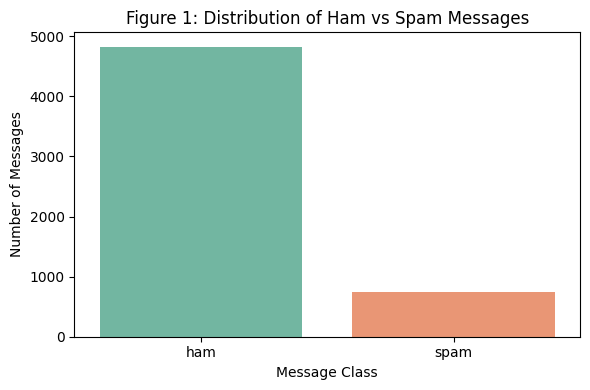

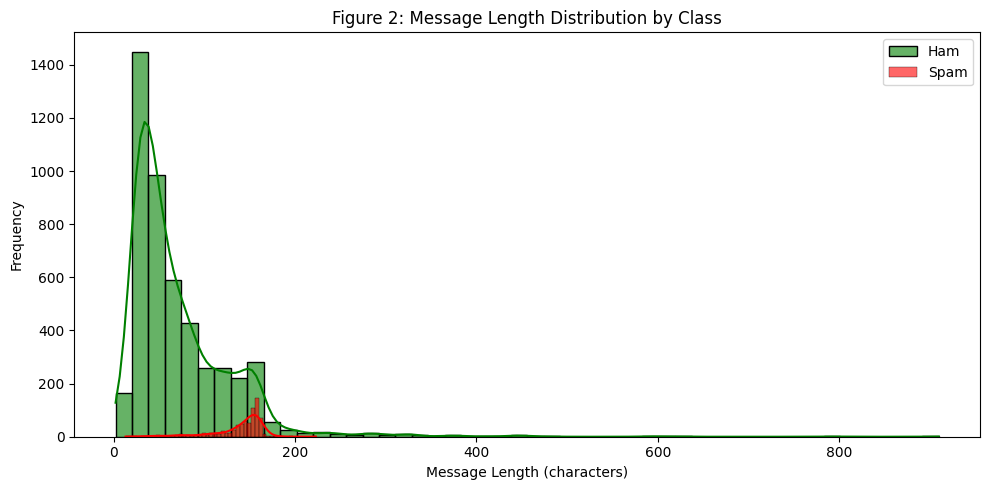

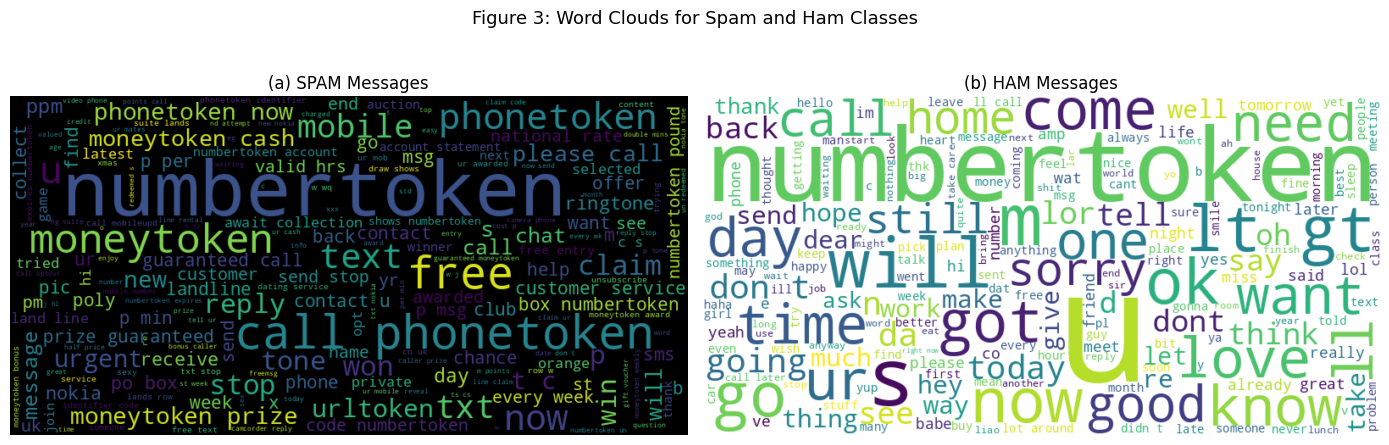

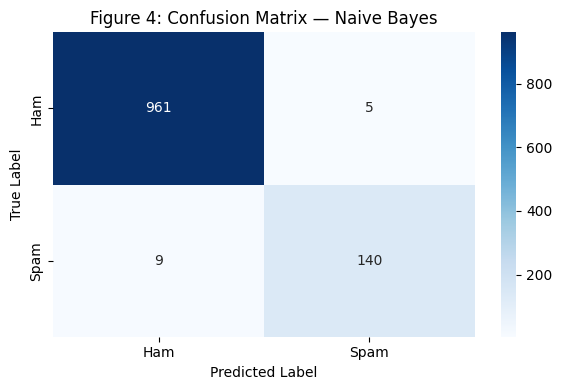

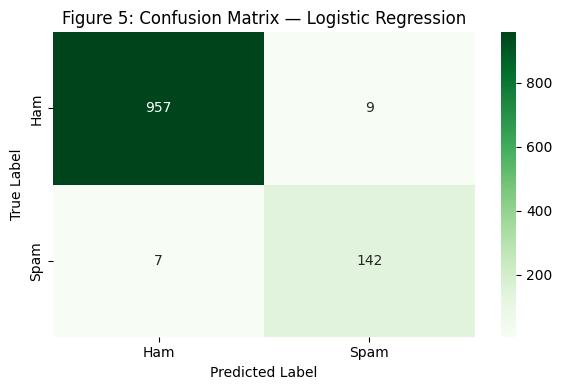

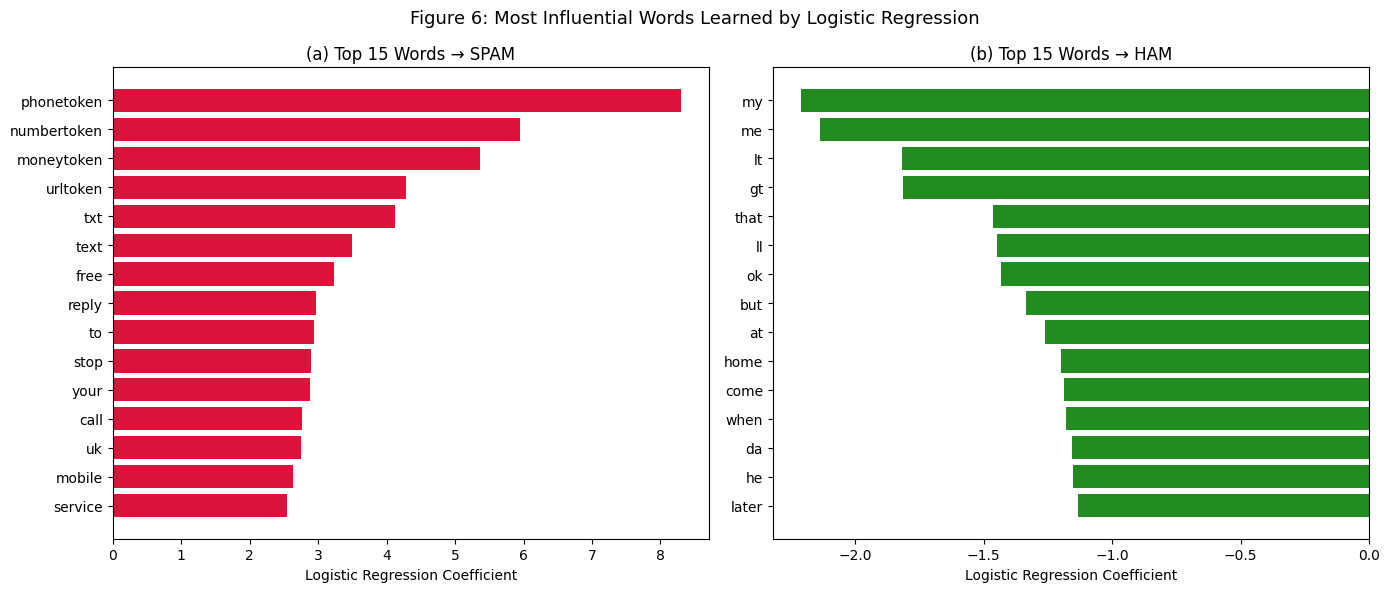




FIGURE 7: MODEL PERFORMANCE COMPARISON
   Metric  Naive Bayes  Logistic Regression
 Accuracy       0.9874               0.9857
Precision       0.9655               0.9404
   Recall       0.9396               0.9530
 F1-Score       0.9524               0.9467


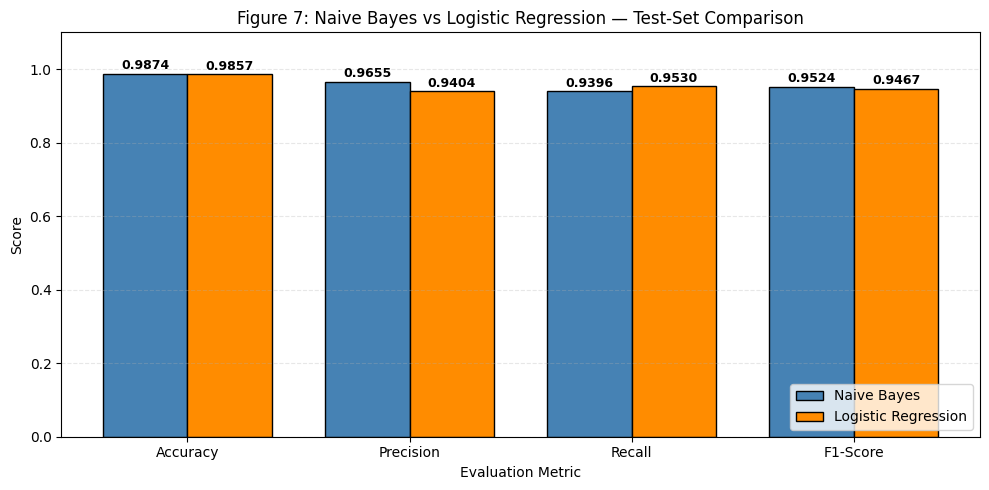




✅ All 7 figures regenerated with numbering, titles, and labeled axes.


In [84]:
# Cell: Regenerate All Figures with Numbers & Captions

import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# ======================================================================
# FIGURE 1: Class Distribution
# ======================================================================
plt.figure(figsize=(6, 4))
sns.countplot(x='label', data=df, hue='label', palette='Set2', legend=False)
plt.title('Figure 1: Distribution of Ham vs Spam Messages')
plt.xlabel('Message Class')
plt.ylabel('Number of Messages')
plt.tight_layout()
plt.show()
print("\n\n")
# ======================================================================
# FIGURE 2: Message Length Distribution
# ======================================================================
plt.figure(figsize=(10, 5))
sns.histplot(df[df['label'] == 'ham']['length'],  bins=50, color='green', label='Ham',  kde=True, alpha=0.6)
sns.histplot(df[df['label'] == 'spam']['length'], bins=50, color='red',   label='Spam', kde=True, alpha=0.6)
plt.title('Figure 2: Message Length Distribution by Class')
plt.xlabel('Message Length (characters)')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()
print("\n\n")
# ======================================================================
# FIGURE 3: Word Clouds — Spam vs Ham
# ======================================================================
spam_words = ' '.join([corpus[i] for i in range(len(df)) if df['label_num'][i] == 1]).split()
ham_words  = ' '.join([corpus[i] for i in range(len(df)) if df['label_num'][i] == 0]).split()

spam_wc = WordCloud(width=800, height=400, background_color='black').generate(' '.join(spam_words))
ham_wc  = WordCloud(width=800, height=400, background_color='white').generate(' '.join(ham_words))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(spam_wc, interpolation='bilinear'); axes[0].axis('off')
axes[0].set_title('(a) SPAM Messages')
axes[1].imshow(ham_wc, interpolation='bilinear');  axes[1].axis('off')
axes[1].set_title('(b) HAM Messages')
fig.suptitle('Figure 3: Word Clouds for Spam and Ham Classes', fontsize=13)
plt.tight_layout()
plt.show()
print("\n\n")
# ======================================================================
# FIGURE 4: Confusion Matrix — Naive Bayes
# ======================================================================
from sklearn.metrics import confusion_matrix
cm_nb = confusion_matrix(Y_test, model.predict(X_test))

plt.figure(figsize=(6, 4))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title('Figure 4: Confusion Matrix — Naive Bayes')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()
print("\n\n")
# ======================================================================
# FIGURE 5: Confusion Matrix — Logistic Regression
# ======================================================================
cm_lr = confusion_matrix(Y_test, lr_model.predict(X_test_tfidf))

plt.figure(figsize=(6, 4))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title('Figure 5: Confusion Matrix — Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()
print("\n\n")
# ======================================================================
# FIGURE 6: Feature Importance (already in M3 — re-emitted for completeness)
# ======================================================================
import pandas as pd
feature_names = tfidf.get_feature_names_out()
coef_df = pd.DataFrame({'word': feature_names, 'coefficient': lr_model.coef_[0]}) \
            .sort_values('coefficient', ascending=False).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
top_spam = coef_df.head(15).iloc[::-1]
top_ham  = coef_df.tail(15)
axes[0].barh(top_spam['word'], top_spam['coefficient'], color='crimson')
axes[0].set_title('(a) Top 15 Words → SPAM')
axes[0].set_xlabel('Logistic Regression Coefficient')
axes[1].barh(top_ham['word'], top_ham['coefficient'], color='forestgreen')
axes[1].set_title('(b) Top 15 Words → HAM')
axes[1].set_xlabel('Logistic Regression Coefficient')
fig.suptitle('Figure 6: Most Influential Words Learned by Logistic Regression', fontsize=13)
plt.tight_layout()
plt.show()
print("\n\n")
# ======================================================================
# FIGURE 7: NB vs LR Comparison (already in M4 — re-emitted here)
# ======================================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate fresh predictions from both models
y_pred_nb = model.predict(X_test)
y_pred_lr = lr_model.predict(X_test_tfidf)


# 2. Calculate Naive Bayes metrics
nb_metrics = [
    accuracy_score(Y_test, y_pred_nb),
    precision_score(Y_test, y_pred_nb, zero_division=0),
    recall_score(Y_test, y_pred_nb, zero_division=0),
    f1_score(Y_test, y_pred_nb, zero_division=0)
]


# 3. Calculate Logistic Regression metrics
lr_metrics = [
    accuracy_score(Y_test, y_pred_lr),
    precision_score(Y_test, y_pred_lr, zero_division=0),
    recall_score(Y_test, y_pred_lr, zero_division=0),
    f1_score(Y_test, y_pred_lr, zero_division=0)
]


# 4. Display numerical comparison
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

comparison_df = pd.DataFrame({
    'Metric': metric_names,
    'Naive Bayes': nb_metrics,
    'Logistic Regression': lr_metrics
})

print("FIGURE 7: MODEL PERFORMANCE COMPARISON")
print("=" * 60)
print(comparison_df.round(4).to_string(index=False))


# 5. Plot comparison
x = np.arange(len(metric_names))
width = 0.38

fig, ax = plt.subplots(figsize=(10, 5))

bars1 = ax.bar(
    x - width/2,
    nb_metrics,
    width,
    label='Naive Bayes',
    color='steelblue',
    edgecolor='black'
)

bars2 = ax.bar(
    x + width/2,
    lr_metrics,
    width,
    label='Logistic Regression',
    color='darkorange',
    edgecolor='black'
)


# 6. Add metric values above bars
for bars in (bars1, bars2):
    for bar in bars:
        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.004,
            f'{height:.4f}',
            ha='center',
            va='bottom',
            fontsize=9,
            fontweight='bold'
        )


# 7. Configure chart
ax.set_ylabel('Score')
ax.set_xlabel('Evaluation Metric')

ax.set_title(
    'Figure 7: Naive Bayes vs Logistic Regression — Test-Set Comparison'
)

ax.set_xticks(x)
ax.set_xticklabels(metric_names)

ax.set_ylim(0, 1.10)

ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

print("\n")

print("\n✅ All 7 figures regenerated with numbering, titles, and labeled axes.")


In [85]:

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
import pandas as pd
import numpy as np

# 1. Define Stratified 5-Fold Cross-Validation
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 2. Define the evaluation metrics
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}

# 3. Define model pipelines
models = {
    'Naive Bayes (Count)': Pipeline([
        ('vectorizer', CountVectorizer(max_features=2500)),
        ('classifier', MultinomialNB())
    ]),

    'Naive Bayes (TF-IDF)': Pipeline([
        ('vectorizer', TfidfVectorizer(max_features=2500)),
        ('classifier', MultinomialNB())
    ]),

    'Logistic Regression (TF-IDF)': Pipeline([
        ('vectorizer', TfidfVectorizer(max_features=2500)),
        ('classifier', LogisticRegression(
            class_weight='balanced',
            max_iter=1000,
            random_state=42
        ))
    ])
}

# 4. Perform cross-validation
cv_results = []

for model_name, pipeline in models.items():

    scores = cross_validate(
        pipeline,
        corpus_train,
        Y_train,
        cv=skf,
        scoring=scoring,
        return_train_score=False,
        n_jobs=-1
    )

    cv_results.append({
        'Model': model_name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1_Score': scores['test_f1'].mean(),
        'Accuracy_STD': scores['test_accuracy'].std(),
        'F1_STD': scores['test_f1'].std()
    })

# 5. Display results
cv_df = pd.DataFrame(cv_results)

print("STRATIFIED 5-FOLD CROSS-VALIDATION RESULTS")
print("=" * 85)
print(cv_df.round(4).to_string(index=False))


STRATIFIED 5-FOLD CROSS-VALIDATION RESULTS
                       Model  Accuracy  Precision  Recall  F1_Score  Accuracy_STD  F1_STD
         Naive Bayes (Count)    0.9843     0.9374  0.9465    0.9418        0.0020  0.0071
        Naive Bayes (TF-IDF)    0.9787     1.0000  0.8412    0.9136        0.0026  0.0111
Logistic Regression (TF-IDF)    0.9812     0.9157  0.9482    0.9312        0.0032  0.0103
